# PathPack v0.5 — иерархический поиск

Блокнот читает измеренный прогон `output/v05_dev` и аудит ошибок v0.4 в `output/v05_audit`. Числа не заданы вручную.

Двухэтапный отбор:

1. **Файлы.** BM25 тела, имена символов и типизированные пути графа дают FileScore. В пул входят файлы зёрен, файлы с raw ≥ 12% лучшего и добор до 8 файлов. Потолок 24 не выбрасывает файлы зёрен.
2. **Фрагменты.** Внутри файла отдельно оцениваются функции, методы и AST-чанки. Формула `0.20·File + 0.50·Chunk + 0.18·Graph + 0.12·Context`. Повтор текста и повтор файла штрафуются, но высокий ChunkScore ослабляет штраф файла. Первый чанк файла получает небольшой бонус, чтобы один файл не занял весь бюджет только за счёт FileScore и чтобы File Recall не схлопнулся.
3. **Бюджет.** Порядок фрагментов один. Контексты 1024, 2048 и 4096 — префиксы этого порядка. Заголовки, пути и сигнатурный якорь входят в стоимость. Соседние строки тела сами по себе не добавляются.

Счётчик токенов: `utf8_bytes_div4_ceil_serialized_context_v1`. Это не токенизатор Gemma. Gold используется только в аудите и в оценке после retrieval.


In [1]:
from pathlib import Path
import csv, gzip, json, sys
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/codegraph_rag').is_dir())
sys.path.insert(0, str(ROOT/'src'))
RUN, AUDIT = ROOT/'output/v05_dev', ROOT/'output/v05_audit'
meta = json.loads((RUN/'run.json').read_text())
summary = list(csv.DictReader((RUN/'summary.csv').open()))
print('tasks', len(meta['issues']), 'counter', meta['token_counter'])
print('embedding', meta['embedding_baseline']['status'], meta['embedding_baseline'].get('reason',''))
print('audit_ok', json.loads((RUN/'audit.json').read_text())['ok'])


tasks 20 counter utf8_bytes_div4_ceil_serialized_context_v1
embedding not_run sentence-transformers is not installed. No weights were downloaded and no lexical method was substituted under this name.
audit_ok True


## Пример двухэтапного поиска

Ниже — реальная диагностика `pathpack-v5` @2048 для первой dev-задачи прогона. Таблица файлов — этап 1. Таблица чанков — этап 2. Эталонные строки в этот пример не подставляются.


In [2]:
diag = next((RUN/'diagnostics').glob('*_v5full_2048.json.gz'))
doc = json.loads(gzip.open(diag).read())
print(doc['instance_id'], 'seeds', doc['seeds'])
print('selected files', doc['selected_files'], 'selected chunks', doc['selected_chunks'])
print('profile', {k: round(doc['profile'][k], 4) for k in ('candidate_sec','graph_sec','file_rank_sec','chunk_score_sec','diversity_sec','query_sec')})
chosen = [row for row in doc['files'] if row['selected']]
chosen.sort(key=lambda row: -row['file_score_raw'])
print('top selected files:')
for row in chosen[:8]:
    print(f"  {row['file_score_raw']:.3f}  {row['path']}  best={row['best_function_id']}")


scikit-learn__scikit-learn-13124 seeds ['sklearn/utils/_show_versions.py::_get_blas_info', 'examples/preprocessing/plot_map_data_to_normal.py::__module__', 'sklearn/model_selection/_split.py::train_test_split', 'sklearn/feature_extraction/dict_vectorizer.py::DictVectorizer._transform']
selected files 15 selected chunks 15
profile {'candidate_sec': 0.1641, 'graph_sec': 0.0918, 'file_rank_sec': 0.0375, 'chunk_score_sec': 0.0343, 'diversity_sec': 0.1382, 'query_sec': 0.477}
top selected files:
  1.000  sklearn/utils/_show_versions.py  best=sklearn/utils/_show_versions.py::_get_blas_info
  0.853  sklearn/model_selection/_split.py  best=sklearn/model_selection/_split.py::train_test_split
  0.843  sklearn/feature_extraction/dict_vectorizer.py  best=sklearn/feature_extraction/dict_vectorizer.py::DictVectorizer._transform
  0.741  sklearn/model_selection/_validation.py  best=sklearn/model_selection/_validation.py::validation_curve
  0.695  sklearn/utils/__init__.py  best=sklearn/utils/__init__

## Граф зависимостей

Рёбра берутся из сохранённого графа той же задачи. На рисунке — функции, которые v0.5 передал в контекст, и рёбра между ними, если статический граф их содержит. Отсутствие ребра на рисунке не означает, что зависимости нет: показаны только выбранные функции.


selected functions shown 15 edges among them 5


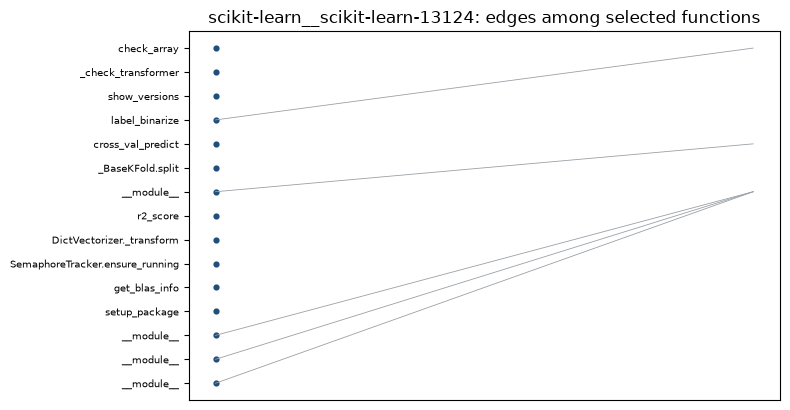

In [3]:
graph_path = RUN/f"{doc['instance_id']}_graph.json.gz"
graph = json.loads(gzip.open(graph_path).read())
selected = {c['function_id'] for c in doc['candidates'] if c.get('selected') and c.get('function_id')}
if len(selected) > 24:
    selected = set(sorted(selected)[:24])
edges = [e for e in graph['edges'] if e['source'] in selected and e['target'] in selected]
print('selected functions shown', len(selected), 'edges among them', len(edges))
fig, ax = plt.subplots(figsize=(8, max(3, 0.28*len(selected))))
names = sorted(selected)
pos = {name: i for i, name in enumerate(names)}
for edge in edges[:80]:
    ax.plot([0, 1], [pos[edge['source']], pos[edge['target']]], color='#9aa0a6', lw=0.6)
ax.scatter([0]*len(names), list(pos.values()), s=12, c='#1f4e79')
ax.set_yticks(list(pos.values()), [name.split('::')[-1][:48] for name in names], fontsize=7)
ax.set_xticks([])
ax.set_title(doc['instance_id'] + ': edges among selected functions')
fig.tight_layout()


## Ранжирование файлов

Полный список выбранных файлов той же задачи, по FileScore. Причина `selected_seed` оставляет файл даже ниже порога.


In [4]:
print(f"{'score':>7} {'reason':<22} path")
for row in chosen:
    print(f"{row['file_score_raw']:7.3f} {row['reason']:<22} {row['path']}")


  score reason                 path
  1.000 selected_seed          sklearn/utils/_show_versions.py
  0.853 selected_seed          sklearn/model_selection/_split.py
  0.843 selected_seed          sklearn/feature_extraction/dict_vectorizer.py
  0.741 selected_threshold     sklearn/model_selection/_validation.py
  0.695 selected_threshold     sklearn/utils/__init__.py
  0.672 selected_seed          examples/preprocessing/plot_map_data_to_normal.py
  0.654 selected_threshold     sklearn/_build_utils/__init__.py
  0.650 selected_threshold     sklearn/utils/estimator_checks.py
  0.623 selected_threshold     sklearn/metrics/pairwise.py
  0.604 selected_threshold     sklearn/externals/joblib/externals/loky/backend/semaphore_tracker.py
  0.598 selected_threshold     setup.py
  0.583 selected_threshold     examples/model_selection/plot_roc_crossval.py
  0.579 selected_threshold     sklearn/preprocessing/label.py
  0.578 selected_threshold     sklearn/linear_model/stochastic_gradient.py
  0.571 s

## Ранжирование функций внутри файла

Для файла с наибольшим FileScore показаны его чанки в порядке v0.5. `chunk_score` — соответствие фрагмента запросу внутри файла, `graph_score` — связь с релевантными функциями, `context_score` — новизна относительно уже выбранного текста.


In [5]:
focus = chosen[0]['path']
local = [c for c in doc['candidates'] if c['path']==focus and c.get('order') is not None]
local.sort(key=lambda c: c['order'])
print(focus)
print(f"{'ord':>4} {'score':>6} {'chunk':>6} {'graph':>6} {'ctx':>6} {'dec':<22} function")
for c in local[:12]:
    print(f"{c['order']:4} {c['score']:6.3f} {c['chunk_score']:6.3f} {c['graph_score']:6.3f} {c['context_score']:6.3f} {c['decision']:<22} {c['qualname']}")


sklearn/utils/_show_versions.py
 ord  score  chunk  graph    ctx dec                    function
   1  0.856  0.556  0.850  0.974 selected               show_versions
  24  0.535  0.803  0.000  0.839 after_budget_cutoff    _get_blas_info
  34  0.446  0.626  0.647  0.819 after_budget_cutoff    _get_deps_info
  49  0.306  0.504  0.480  0.742 after_budget_cutoff    _get_sys_info
 200  0.102  0.150  0.083  0.778 after_budget_cutoff    _get_deps_info.get_version


## Найденные и эталонные строки

Цвета построены аудитом **после** retrieval v0.4 @2048, потому что вопрос этого раздела — почему правильный файл не передаёт нужные строки. Зелёный: нужная строка попала в контекст. Красный: нужная строка пропущена. Жёлтый: выбранный фрагмент не пересекается с эталонным исправлением. Эталон не участвовал в ранжировании.


case counts {'D': 12, 'E': 11, 'F': 16, 'A': 10, 'C': 8, 'B': 2}
reports ['sympy__sympy-24213', 'sphinx-doc__sphinx-7985', 'astropy__astropy-8707', 'django__django-12276', 'django__django-14580', 'scikit-learn__scikit-learn-13439', 'django__django-14725', 'matplotlib__matplotlib-23476', 'mwaskom__seaborn-3187', 'psf__requests-1766']
line figure True


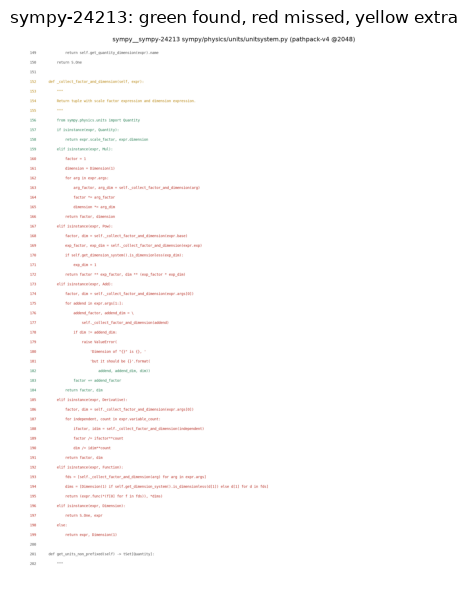

In [6]:
case = json.loads((AUDIT/'summary.json').read_text())
print('case counts', case['case_counts'])
print('reports', case['reports'])
image = AUDIT/'figures'/'sympy__sympy-24213_lines.png'
print('line figure', image.exists())
pixels = plt.imread(image)
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(pixels); ax.axis('off')
ax.set_title('sympy-24213: green found, red missed, yellow extra')
fig.tight_layout()


## Recall по бюджетам

Macro mean только по задачам, где метрика определена. Changed Line Recall не включает вставки, которых нет в `base_commit`.


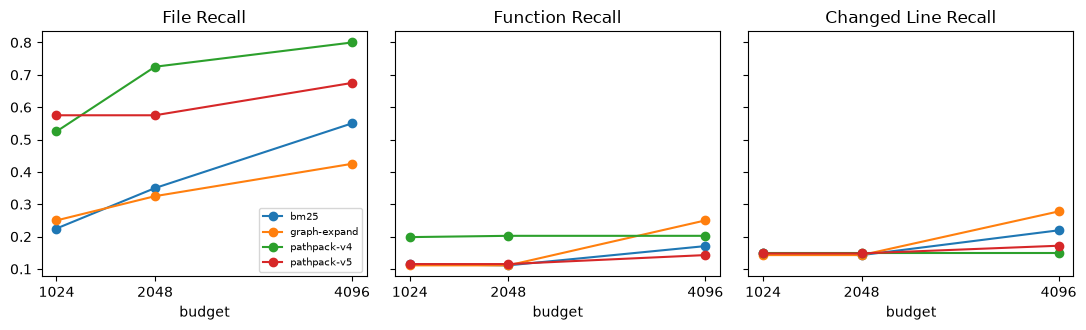

In [7]:
methods = ('bm25','graph-expand','pathpack-v4','pathpack-v5')
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, metric, title in zip(axes, ('file_recall','function_recall','changed_line_recall'), ('File Recall','Function Recall','Changed Line Recall')):
    for method in methods:
        part = sorted((r for r in summary if r['method']==method), key=lambda r: int(r['budget']))
        ax.plot([int(r['budget']) for r in part], [float(r[metric]) for r in part], marker='o', label=method)
    ax.set_title(title); ax.set_xlabel('budget'); ax.set_xticks([1024,2048,4096])
axes[0].legend(fontsize=7)
fig.tight_layout()


## Абляции @2048

Каждая строка выключает один механизм v0.5. `no-hierarchy` убирает отбор файлов и внутрифайловую перенормировку. `no-graph` обнуляет граф и в FileScore, и в GraphScore. `no-diversity` убирает штраф повтора файла и бонус первого чанка. `no-chunking` берёт функции целиком. `no-file-score` обнуляет α, но не меняет состав пула файлов.


In [8]:
cols = ['method','file_recall','function_recall','complete_function_recall','changed_line_recall','relevant_line_density','latency_sec','useful_functions_per_1k']
print(' | '.join(cols))
for row in summary:
    if row['budget']=='2048' and row['method'].startswith('pathpack-v5'):
        print(' | '.join(row[c] for c in cols))


method | file_recall | function_recall | complete_function_recall | changed_line_recall | relevant_line_density | latency_sec | useful_functions_per_1k
pathpack-v5 | 0.575 | 0.11507936507936509 | 0.05952380952380952 | 0.1479591836734694 | 0.165625 | 0.4955010646255687 | 0.08179311512548398
pathpack-v5/no-chunking | 0.8 | 0.08333333333333333 | 0.08333333333333333 | 0.07142857142857142 | 0.08333333333333333 | 0.3569178729492705 | 0.056802601167391394
pathpack-v5/no-diversity | 0.575 | 0.16269841269841268 | 0.10714285714285715 | 0.1717687074829932 | 0.04071332154137455 | 0.36533387282979674 | 0.24630927687276724
pathpack-v5/no-file-score | 0.575 | 0.14285714285714288 | 0.0873015873015873 | 0.1479591836734694 | 0.165625 | 0.42726715001044796 | 0.10890653436728664
pathpack-v5/no-graph | 0.675 | 0.1111111111111111 | 0.05555555555555555 | 0.16666666666666669 | 0.13304347826086957 | 0.34978994371485894 | 0.054399959260622924
pathpack-v5/no-hierarchy | 0.7 | 0.11507936507936509 | 0.059523809523

## Latency

Время запроса не включает сканирование репозитория и построение индекса. Профиль усреднён по максимальному бюджету, чтобы три бюджета одной задачи не посчитались трижды.


stage means, seconds
pathpack-v5 {'graph_sec': 0.0572, 'diversity_sec': 0.1485, 'chunk_score_sec': 0.0608, 'query_sec': 0.4956}
pathpack-v5/no-diversity {'graph_sec': 0.0873, 'diversity_sec': 0.0214, 'chunk_score_sec': 0.0748, 'query_sec': 0.3654}
pathpack-v5/no-graph {'graph_sec': 0.0, 'diversity_sec': 0.1369, 'chunk_score_sec': 0.0528, 'query_sec': 0.3499}


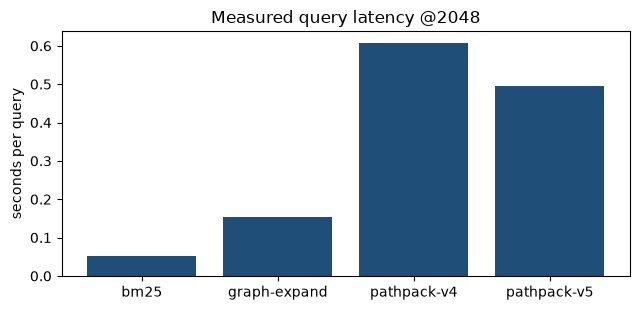

In [9]:
methods = ('bm25','graph-expand','pathpack-v4','pathpack-v5')
main = [next(r for r in summary if r['method']==m and r['budget']=='2048') for m in methods]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar([r['method'] for r in main], [float(r['latency_sec']) for r in main], color='#1f4e79')
ax.set_ylabel('seconds per query')
ax.set_title('Measured query latency @2048')
fig.tight_layout()
profile = list(csv.DictReader((RUN/'stage_profile_mean.csv').open()))
print('stage means, seconds')
for row in profile:
    if row['method'] in {'pathpack-v5','pathpack-v5/no-graph','pathpack-v5/no-diversity'}:
        print(row['method'], {k: round(float(row[k]), 4) for k in ('graph_sec','diversity_sec','chunk_score_sec','query_sec')})


## Выводы и ограничения

Двухэтапный поиск на этих 20 задачах не улучшил локализацию. При 2048 токенах File Recall 0.5750 против 0.7250 у v0.4, Function Recall 0.1151 против 0.2024, Complete Function Recall 0.0595 против 0.0913, Changed Line Recall 0.1480 против 0.1480. По File Recall и Function Recall у v0.5 нет побед над v0.4; Changed Line Recall совпал на всех 14 оцениваемых задачах. Метрики v0.5 при 1024 и 2048 совпали: лишняя тысяча токенов ушла в первые чанки новых, неэталонных файлов. Абляция no-hierarchy возвращает File Recall к 0.7000 и не меняет Function и Changed Line Recall. Отключение графа не ухудшает локализацию строк. Это одна зависимая выборка. Интервалы bootstrap в отчёте важнее разницы средних. Holdout из 60 задач не оценивался. Embedding retrieval не запускался.

Ограничения: 20 задач, неполная разметка на большинстве из них, один проход latency, статический граф, невыполненный embedding baseline и не оценённый holdout `output/v05_holdout` (60 instance id, seed 44, пересечение с dev и прежними списками равно нулю). Подробности и парные доверительные интервалы — в `docs/PATHPACK_V05_REPORT_RU.md`.
